# Análisis exploratorio de datos climatológicos de CONAGUA

**Proyecto:** Análisis de la producción agrícola en México  
**Fuente:** Servicio Meteorológico Nacional (CONAGUA)  
**Periodo:** 1981–2022

## Objetivo

Analizar la distribución espacial, cobertura temporal,
comportamiento climático y consistencia de las observaciones
mensuales provenientes de estaciones climatológicas mexicanas.

El propósito es identificar datos confiables para su posterior
integración con la información de producción agrícola.

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import requests

from proyecto_agronomia.datasets.clima_con import (
    cargar_json_conagua,
    leer_catalogo_conagua,
    descargar_catalogo_conagua,
    crear_geodataframe_conagua,
    normalizar_clave_conagua,
    calcular_precipitacion_media_anual,
    calcular_precipitacion_por_anio,
)

from proyecto_agronomia.config import (
    CONAGUA_PROCESSED_DIR,
    CONAGUA_MEXICO_GEOJSON_URL,
)

ruta_estaciones = (
    CONAGUA_PROCESSED_DIR
    / "estaciones_seleccionadas_continentales_1981_2022.csv"
)

2026-10-16 20:16:12.955 | INFO     | proyecto_agronomia.config:<module>:14 - PROJ_ROOT path is: B:\MCD2\JW\agro\proyecto_agronomia


## 1. Carga y exploración de observaciones climatológicas

Se integran los archivos JSON de las estaciones seleccionadas
en una tabla nacional de observaciones mensuales.

Se revisa la estructura del dataset, las variables disponibles,
los periodos de observación y la presencia de valores faltantes.

In [2]:
df_clima = cargar_json_conagua()

print("Dimensiones:", df_clima.shape)

print(
    "Estaciones:",
    df_clima["estacion"].nunique()
)

print(
    "Variables:",
    df_clima["variable"].nunique()
)

print(
    "Periodo:",
    df_clima["anio"].min(),
    "-",
    df_clima["anio"].max()
)

display(df_clima.head())

Leyendo JSON CONAGUA: 100%|██████████| 526/526 [00:03<00:00, 156.37it/s]


2026-10-16 20:16:18.358 | SUCCESS  | proyecto_agronomia.datasets.clima_con:cargar_json_conagua:1039 - CONAGUA: 526 JSON leídos, 1,247,808 observaciones extraídas, 0 archivos con errores.
Dimensiones: (1247808, 5)
Estaciones: 525
Variables: 8
Periodo: 1981 - 2022


,estacion,variable,anio,mes,valor
0,01001,LLUVIA MAXIMA 24 H.,1981,1,8.5
1,01001,LLUVIA MAXIMA 24 H.,1981,2,4.4
2,01001,LLUVIA MAXIMA 24 H.,1981,3,0.0
3,01001,LLUVIA MAXIMA 24 H.,1981,4,10.8
4,01001,LLUVIA MAXIMA 24 H.,1981,5,5.0


In [3]:
resumen_variables = (
    df_clima.groupby("variable")
    .agg(
        registros=("valor", "size"),
        validos=("valor", "count"),
        estaciones=("estacion", "nunique"),
        minimo=("valor", "min"),
        maximo=("valor", "max"),
    )
    .reset_index()
)

resumen_variables["porcentaje_validos"] = (
    100
    * resumen_variables["validos"]
    / resumen_variables["registros"]
)

display(
    resumen_variables.sort_values(
        "registros",
        ascending=False,
    )
)

,variable,registros,validos,estaciones,minimo,maximo,porcentaje_validos
1,LLUVIA MAXIMA 24 H.,168036,162780,523,0.0,1058.00,96.872099
2,LLUVIA TOTAL MENSUAL,168036,162780,523,0.0,4359.20,96.872099
3,TEMPERATURA MAXIMA EXTREMA,163140,155809,519,1.0,55.00,95.506314
4,TEMPERATURA MAXIMA PROMEDIO,163140,155809,519,1.0,50.10,95.506314
6,TEMPERATURA MINIMA EXTREMA,163140,155809,519,-26.0,29.00,95.506314
5,TEMPERATURA MEDIA MENSUAL,163140,155809,519,-0.8,38.80,95.506314
7,TEMPERATURA MINIMA PROMEDIO,163140,155809,519,-13.8,32.90,95.506314
0,EVAPORACION MENSUAL,96036,88909,453,0.0,2784.52,92.578825


In [4]:
columnas_clave = [
    "estacion",
    "variable",
    "anio",
    "mes",
]

duplicados = df_clima.duplicated(
    subset=columnas_clave,
    keep=False,
)

print(
    "Registros duplicados:",
    duplicados.sum()
)

display(
    df_clima.loc[duplicados]
    .sort_values(columnas_clave)
    .head(20)
)

Registros duplicados: 0


,estacion,variable,anio,mes,valor


In [5]:
variables_revisar = [
    "LLUVIA TOTAL MENSUAL",
    "EVAPORACION MENSUAL",
    "TEMPERATURA MAXIMA PROMEDIO",
    "TEMPERATURA MINIMA PROMEDIO",
]

df_extremos = (
    df_clima[
        df_clima["variable"].isin(variables_revisar)
    ]
    .dropna(subset=["valor"])
    .sort_values("valor", ascending=False)
)

for variable in variables_revisar:

    print(f"\nVARIABLE: {variable}")

    display(
        df_extremos[
            df_extremos["variable"] == variable
        ][
            ["estacion", "anio", "mes", "valor"]
        ].head(10)
    )


VARIABLE: LLUVIA TOTAL MENSUAL


,estacion,anio,mes,valor
524627,13144,1995,12,4359.2
1145279,30318,1984,12,4146.3
243250,07164,2010,11,3471.7
1053791,27070,2008,12,3389.1
233469,07085,2013,10,3253.0
262691,07386,2010,12,3040.5
236075,07106,1982,12,2918.7
1053899,27070,2017,12,2853.9
1137239,30167,1988,12,2752.5
523055,13104,1984,12,2745.0



VARIABLE: EVAPORACION MENSUAL


,estacion,anio,mes,valor
902087,24008,1990,12,2784.52
769895,20328,1987,12,2774.80
1023383,26232,2004,12,2713.74
428375,12007,1984,12,2680.21
212783,08332,1993,12,2668.45
1012631,26206,2004,12,2655.14
419927,10174,2017,12,2649.84
1222511,32107,1998,12,2647.44
175463,08077,2007,12,2641.40
1246151,32177,2011,12,2639.09



VARIABLE: TEMPERATURA MAXIMA PROMEDIO


,estacion,anio,mes,valor
700105,19097,2001,2,50.1
55599,02138,1991,4,49.3
55614,02138,1992,7,49.2
55615,02138,1992,8,49.0
700106,19097,2001,3,49.0
55624,02138,1993,5,48.9
55613,02138,1992,6,48.9
55636,02138,1994,5,48.9
55598,02138,1991,3,48.9
177028,08084,1994,5,48.7



VARIABLE: TEMPERATURA MINIMA PROMEDIO


,estacion,anio,mes,valor
704019,19127,2005,4,32.9
1153027,30382,2013,8,32.3
974836,26049,1987,5,31.4
59202,02154,2017,7,30.9
974835,26049,1987,4,30.8
305585,05144,2013,6,30.4
972750,26035,2019,7,30.2
305586,05144,2013,7,30.2
121855,03191,2015,8,30.1
14647,02004,2020,8,30.0


In [6]:
df_temperaturas = (
    df_clima[
        df_clima["variable"].isin([
            "TEMPERATURA MAXIMA PROMEDIO",
            "TEMPERATURA MEDIA MENSUAL",
            "TEMPERATURA MINIMA PROMEDIO",
        ])
    ]
    .pivot_table(
        index=["estacion", "anio", "mes"],
        columns="variable",
        values="valor",
        aggfunc="first",
    )
    .reset_index()
)

inconsistencias = df_temperaturas[
    (
        df_temperaturas["TEMPERATURA MINIMA PROMEDIO"]
        > df_temperaturas["TEMPERATURA MEDIA MENSUAL"]
    )
    |
    (
        df_temperaturas["TEMPERATURA MEDIA MENSUAL"]
        > df_temperaturas["TEMPERATURA MAXIMA PROMEDIO"]
    )
]

print(
    "Observaciones con temperaturas inconsistentes:",
    len(inconsistencias)
)

display(inconsistencias.head(20))

Observaciones con temperaturas inconsistentes: 0


variable,estacion,anio,mes,TEMPERATURA MAXIMA PROMEDIO,TEMPERATURA MEDIA MENSUAL,TEMPERATURA MINIMA PROMEDIO


In [7]:
df_estaciones = pd.read_csv(
    ruta_estaciones,
    dtype={"estacion": str},
)

print(df_estaciones.columns.tolist())

display(df_estaciones.head())

['estacion', 'nombre', 'estado', 'municipio', 'situacion', 'inicio', 'mas_reciente', 'latitud', 'longitud', 'altitud', 'url_mensual']


,estacion,nombre,estado,municipio,situacion,inicio,mas_reciente,latitud,longitud,altitud,url_mensual
0,1001,AGUASCALIENTES (OBS),AGUASCALIENTES,AGUASCALIENTES,OPERANDO,1878-01-01,2026-10-09,21.850278,-102.290833,1890.8,https://smn.conagua.gob.mx/tools/RESOURCES/Nor...
1,1088,COSIO,AGUASCALIENTES,COSÍO,OPERANDO,1978-08-01,2026-10-09,22.362778,-102.296944,2022.7,https://smn.conagua.gob.mx/tools/RESOURCES/Nor...
2,1078,EL OCOTE,AGUASCALIENTES,CALVILLO,OPERANDO,1980-04-01,2024-12-31,21.890278,-102.832500,2328.9,https://smn.conagua.gob.mx/tools/RESOURCES/Nor...
3,2072,PRESA EMILIO LOPEZ ZAMORA,BAJA CALIFORNIA,ENSENADA,OPERANDO,1923-01-01,2026-10-09,31.895833,-115.597222,43.0,https://smn.conagua.gob.mx/tools/RESOURCES/Nor...
4,2061,SANTA GERTRUDIS,BAJA CALIFORNIA,SAN QUINTÍN,SUSPENDIDA,1955-10-01,1991-12-31,28.075000,-113.091667,400.0,https://smn.conagua.gob.mx/tools/RESOURCES/Nor...


In [8]:
df_clima["estacion"] = normalizar_clave_conagua(
    df_clima["estacion"]
)

df_estaciones["estacion"] = normalizar_clave_conagua(
    df_estaciones["estacion"]
)

## 2. Cobertura espacial de precipitación

Se calcula el porcentaje de meses con datos válidos de
precipitación para cada estación climatológica entre
1981 y 2022.

El periodo comprende 42 años, equivalentes a 504 meses.

In [9]:
df_lluvia = df_clima[
    df_clima["variable"] == "LLUVIA TOTAL MENSUAL"
].copy()

df_lluvia = df_lluvia[
    df_lluvia["anio"].between(1981, 2022)
    & df_lluvia["mes"].between(1, 12)
]

# Una observación por estación, año y mes
df_lluvia = df_lluvia.drop_duplicates(
    subset=["estacion", "anio", "mes"]
)

df_cobertura = (
    df_lluvia.groupby("estacion")
    .agg(
        meses_validos=("valor", "count"),
        meses_registrados=("valor", "size"),
    )
    .reset_index()
)

TOTAL_MESES = (2022 - 1981 + 1) * 12

df_cobertura["cobertura_pct"] = (
    df_cobertura["meses_validos"]
    / TOTAL_MESES
    * 100
)

gdf_estaciones = crear_geodataframe_conagua(
    df_estaciones,
    df_cobertura,
)

print("Estaciones seleccionadas:", len(df_estaciones))

print(
    "Estaciones con precipitación:",
    gdf_estaciones["cobertura_pct"].notna().sum()
)

print(
    "Estaciones sin precipitación:",
    gdf_estaciones["cobertura_pct"].isna().sum()
)

print(
    "Cobertura media:",
    round(
        gdf_estaciones["cobertura_pct"].mean(),
        2,
    ),
    "%",
)
display(
    gdf_estaciones[
        ["estacion", "estado", "meses_validos", "cobertura_pct"]
    ].head()
)

Estaciones seleccionadas: 531
Estaciones con precipitación: 523
Estaciones sin precipitación: 8
Cobertura media: 61.75 %


,estacion,estado,meses_validos,cobertura_pct
0,01001,AGUASCALIENTES,499.0,99.007937
1,01088,AGUASCALIENTES,500.0,99.206349
2,01078,AGUASCALIENTES,498.0,98.809524
3,02072,BAJA CALIFORNIA,504.0,100.000000
4,02061,BAJA CALIFORNIA,112.0,22.222222


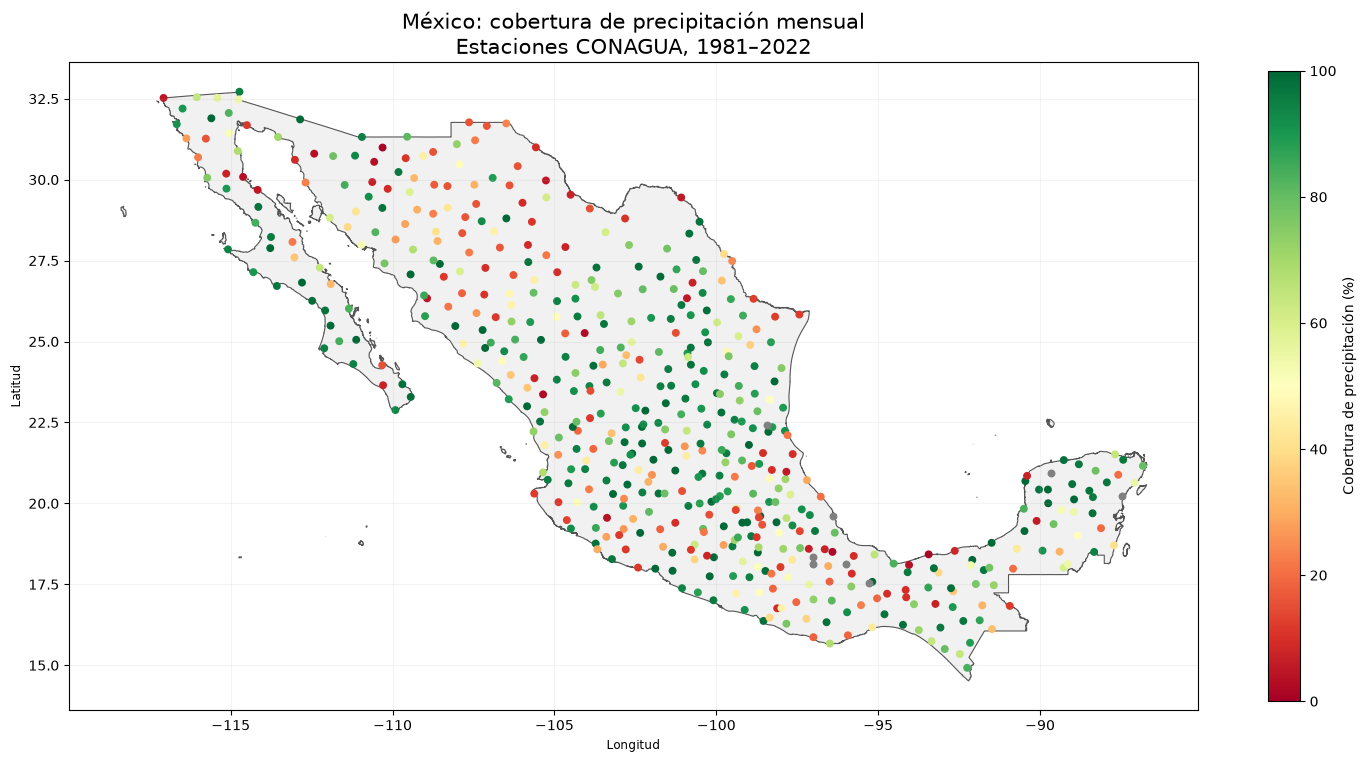

In [10]:
respuesta = requests.get(
    CONAGUA_MEXICO_GEOJSON_URL,
    timeout=30,
)
respuesta.raise_for_status()

metadata = respuesta.json()

url_geojson = metadata["gjDownloadURL"]

mexico = gpd.read_file(url_geojson).to_crs(
    gdf_estaciones.crs
)

fig, ax = plt.subplots(figsize=(15, 10))

# Contorno de México
mexico.plot(
    ax=ax,
    color="#f1f1f1",
    edgecolor="#555555",
    linewidth=0.8,
)

# Estaciones con cobertura conocida
gdf_estaciones.plot(
    ax=ax,
    column="cobertura_pct",
    cmap="RdYlGn",
    vmin=0,
    vmax=100,
    markersize=22,
    legend=True,
    legend_kwds={
        "label": "Cobertura de precipitación (%)",
        "shrink": 0.65,
    },
    missing_kwds={
        "color": "gray",
        "label": "Sin registros de precipitación",
    },
)

ax.set_title(
    "México: cobertura de precipitación mensual\n"
    "Estaciones CONAGUA, 1981–2022",
    fontsize=15,
)

ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")

ax.set_aspect("equal")
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()

In [11]:
print(
    gdf_estaciones["cobertura_pct"].describe()
)

print("\nEstaciones con cobertura ≥ 80 %:")

print(
    (
        gdf_estaciones["cobertura_pct"] >= 80
    ).sum()
)

print("\nEstaciones con cobertura inferior al 50 %:")

print(
    (
        gdf_estaciones["cobertura_pct"] < 50
    ).sum()
)

count    523.000000
mean      61.754530
std       34.284882
min        0.793651
25%       25.595238
50%       74.404762
75%       94.742063
max      100.000000
Name: cobertura_pct, dtype: float64

Estaciones con cobertura ≥ 80 %:
231

Estaciones con cobertura inferior al 50 %:
197


In [12]:
df_precipitacion = calcular_precipitacion_media_anual(
    df_clima,
    min_anios=10,
)

gdf_precipitacion = crear_geodataframe_conagua(
    df_estaciones,
    df_precipitacion,
)

print("Estaciones seleccionadas:", len(gdf_precipitacion))

print(
    "Estaciones con precipitación calculada:",
    gdf_precipitacion[
        "precipitacion_media_anual"
    ].notna().sum()
)

display(
    gdf_precipitacion[
        [
            "estacion",
            "estado",
            "precipitacion_media_anual",
            "anios_completos",
        ]
    ].sort_values(
        "precipitacion_media_anual",
        ascending=False,
    ).head(15)
)

Estaciones seleccionadas: 531
Estaciones con precipitación calculada: 386


,estacion,estado,precipitacion_media_anual,anios_completos
75,07106,CHIAPAS,3628.595000,34.0
78,07393,CHIAPAS,3509.070741,27.0
68,07154,CHIAPAS,3489.758571,14.0
446,27070,TABASCO,3483.160976,41.0
497,30167,VERACRUZ DE IGNACIO DE LA LLAVE,2817.923684,38.0
311,20113,OAXACA,2815.674667,30.0
212,13144,HIDALGO,2811.507931,29.0
66,07085,CHIAPAS,2626.044828,29.0
479,30382,VERACRUZ DE IGNACIO DE LA LLAVE,2613.605556,18.0
443,27047,TABASCO,2543.416667,24.0


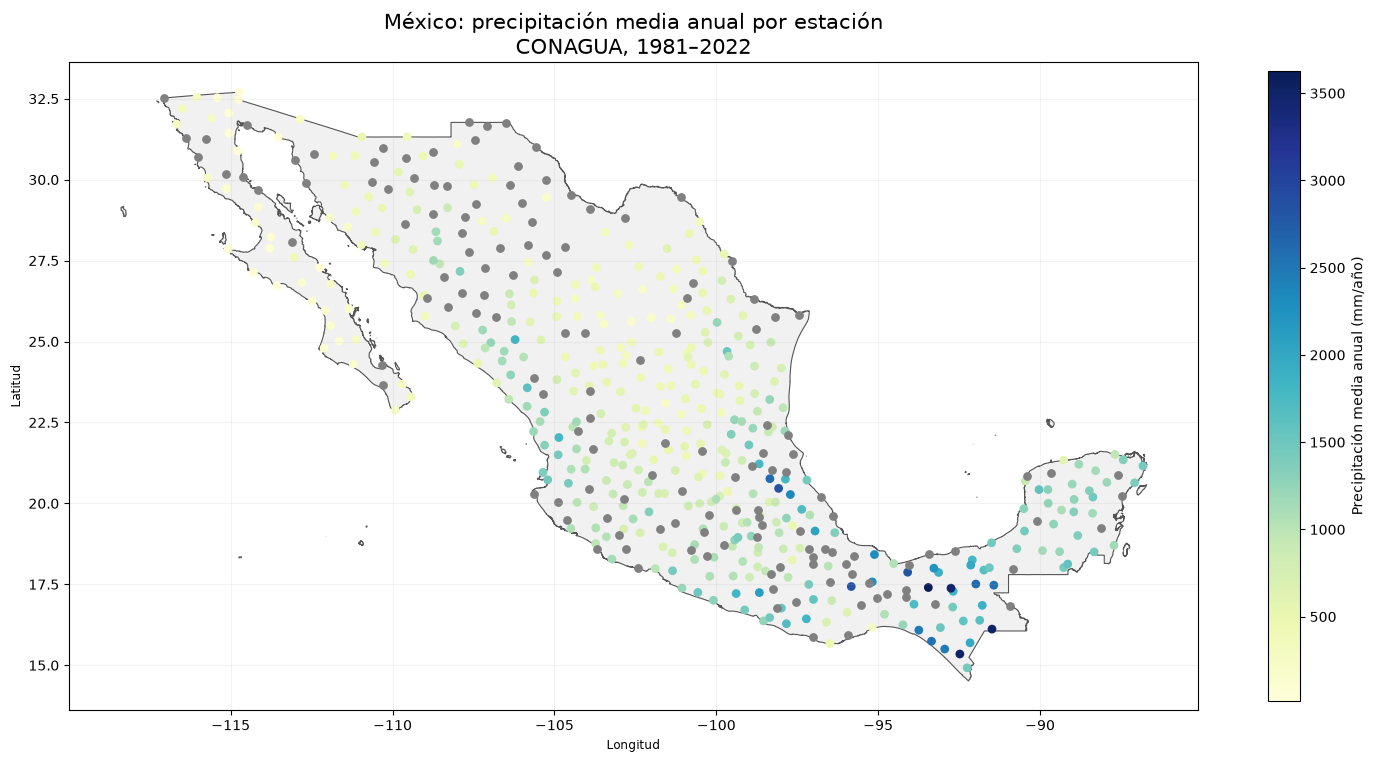

In [13]:
fig, ax = plt.subplots(figsize=(15, 10))

mexico.plot(
    ax=ax,
    color="#f1f1f1",
    edgecolor="#555555",
    linewidth=0.8,
)

gdf_precipitacion.plot(
    ax=ax,
    column="precipitacion_media_anual",
    cmap="YlGnBu",
    markersize=28,
    legend=True,
    legend_kwds={
        "label": "Precipitación media anual (mm/año)",
        "shrink": 0.65,
    },
    missing_kwds={
        "color": "gray",
        "label": "Datos insuficientes",
    },
)

ax.set_title(
    "México: precipitación media anual por estación\n"
    "CONAGUA, 1981–2022",
    fontsize=15,
)

ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_aspect("equal")
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()

In [16]:
df_anual = calcular_precipitacion_por_anio(df_clima)

gdf_anual = crear_geodataframe_conagua(
    df_estaciones,
    df_anual,
    validacion="one_to_many",
)

TypeError: crear_geodataframe_conagua() got an unexpected keyword argument 'validacion'